In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
import os
import torch
from torch import nn
from torch.nn import functional as F
from collections import deque

# For small network parallelism has kernel overhead
torch.set_num_threads(1)

In [2]:
# Critic Network
class Critic(nn.Module):
    def __init__(self, num_states, num_actions):
        super().__init__()
        self.fc1 = nn.Linear(num_states, 64)
        self.fc2 = nn.Linear(64, 64)
        self.out = nn.Linear(64, num_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)

# Actor Network
class Actor(nn.Module):
    def __init__(self, num_states, num_actions):
        super().__init__()
        self.fc1 = nn.Linear(num_states, 64)
        self.fc2 = nn.Linear(64, 64)
        self.out = nn.Linear(64, num_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)

# memory for experience replay
class ReplayMemory():
    def __init__(self, maxlen):
        self.memory = deque([], maxlen=maxlen)

    def append(self, transition):
        self.memory.append(transition)

    def sample(self, sample_size):
        return random.sample(self.memory, sample_size)

    def __len__(self):
        return len(self.memory)

# the observation is a numpy array, net input is a float32 tensor
def state_to_nn_input(state):
    return torch.tensor(state, dtype=torch.float32)

# one training step of the critic and actor nets on a batch from memory
def optimize(discount_factor_g, alpha, batch, actor_nn, critic_nn, critic_target_nn, loss_fn, optimizer_critic, optimizer_actor):

    states = torch.stack([state_to_nn_input(s) for s, a, ns, r, t in batch]) # (batch_size, num_states)
    actions = torch.tensor([a for s, a, ns, r, t in batch], dtype=torch.int64).unsqueeze(-1) # (batch_size, 1) for gather()
    next_states = torch.stack([state_to_nn_input(ns) for s, a, ns, r, t in batch]) # (batch_size, num_states)
    rewards = torch.tensor([r for s, a, ns, r, t in batch], dtype=torch.float32) # (batch_size,)
    terminated_flags = torch.tensor([float(t) for s, a, ns, r, t in batch], dtype=torch.float32) # (batch_size,)

    # Q(S, A) for the current state and the actions that were taken from that state
    # gather() picks the Q value of the action that was taken
    q_values = critic_nn(states)
    current_q_values = q_values.gather(1, actions).squeeze(-1)

    actor_outputs = actor_nn(states)
    actions_probs = torch.distributions.Categorical(logits=actor_outputs).probs
    # log pi(a|S) for all actions
    # first softmax to go from logit to probability
    # second log
    actions_log_probs = F.log_softmax(actor_outputs, dim=1)

    with torch.no_grad(): # the TD target is a fixed label, no gradients through actor_nn or critic_target_nn here
        # soft value of the next state under the current actor
        # V(S') = sum_a' pi(a'|S') * [Q_target(S', a') - alpha * log pi(a'|S')]
        # -log pi is the entropy term (scaled by alpha), so the critic now also values future randomness
        # adding this to critic because our objective now changed to cumulative reward + entropy
        next_actor_outputs = actor_nn(next_states)
        next_actions_probs = torch.distributions.Categorical(logits=next_actor_outputs).probs
        next_actions_log_probs = F.log_softmax(next_actor_outputs, dim=1)
        next_q_values = (next_actions_probs * (critic_target_nn(next_states) - alpha * next_actions_log_probs)).sum(dim=1)
        # the value of a terminal state is 0
        next_q_values[terminated_flags == 1] = 0.0

        # 1 step soft TD target = reward + gamma * V(S')
        target_q_values = rewards + (discount_factor_g * next_q_values)

    loss_critic = loss_fn(current_q_values, target_q_values)
    # actor maximizes expected Q + alpha * entropy
    # sum over all actions, mean over all samples in the batch
    # negative because we wanna maximize Q + entropy, optimizer minimizes
    # detach q_values so the actor loss does not backprop into the critic
    loss_actor = -(actions_probs * (q_values.detach() - alpha * actions_log_probs)).sum(dim=1).mean()

    # learning critic
    optimizer_critic.zero_grad()
    loss_critic.backward()
    # clip gradients to prevent exploding gradients
    torch.nn.utils.clip_grad_norm_(critic_nn.parameters(), max_norm=1.0)
    optimizer_critic.step()

    # learning actor
    optimizer_actor.zero_grad()
    loss_actor.backward()
    optimizer_actor.step()

In [3]:
# Discrete Soft Actor Critic
# Here actions are discrete so we can find actor gradient directly!
env = gym.make("CartPole-v1", render_mode=None)

# env parameters
num_states = env.observation_space.shape[0] # (cart x, cart x_dot, pole theta, pole theta_dot)  # type: ignore
num_actions = env.action_space.n # (left or right)  # type: ignore

# hyperparameters
num_episodes = 5000 # num of epi to train
discount_factor_g = 0.99
alpha = 0.2 # entropy temperature, how much randomness is worth vs reward

# all networks
actor_nn = Actor(num_states=num_states, num_actions=num_actions)

critic_nn = Critic(num_states=num_states, num_actions=num_actions)
critic_target_nn = Critic(num_states=num_states, num_actions=num_actions)

step_count = 0
network_sync_rate = 500 # after 500 steps copy the critic net to the critic target net

# training parameters
batch_size = 64
learning_rate = 0.001
loss_fn = nn.MSELoss()
optimizer_critic = torch.optim.Adam(critic_nn.parameters(), lr=learning_rate)
optimizer_actor = torch.optim.Adam(actor_nn.parameters(), lr=learning_rate)

# memory for recording transitions
replay_memory_size = 5000
memory = ReplayMemory(replay_memory_size)

# to track reward per episode
reward_per_episode = np.zeros(num_episodes)


In [4]:
for i_episode in range(num_episodes):

    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    while (not terminated and not truncated):
        with torch.no_grad():
            actor_input = state_to_nn_input(state).unsqueeze(0)
            actor_output = actor_nn(actor_input)
            action = torch.distributions.Categorical(logits=actor_output).sample().item()

        next_state, reward, terminated, truncated, info = env.step(action)

        # Termination: Pole Angle is greater than ±12°
        # Termination: Cart Position is greater than ±2.4
        # Truncation: Episode length is greater than 500
        # save terminated not truncated, at 500 steps the pole is still up so S' still has value
        memory.append((state, action, next_state, reward, terminated))

        state = next_state
        episode_reward += float(reward)
        step_count += 1

        # optimize at every step, taking a sample from memory
        # start this when memory size > batch size
        if len(memory) > batch_size:
            batch = memory.sample(batch_size)
            optimize(discount_factor_g, alpha, batch, actor_nn, critic_nn, critic_target_nn, loss_fn, optimizer_critic, optimizer_actor)

        # copy the critic net to the critic target net
        if step_count % network_sync_rate == 0:
            critic_target_nn.load_state_dict(critic_nn.state_dict())

    # keep track of reward at every episode
    reward_per_episode[i_episode] = episode_reward

    # progress report
    if (i_episode + 1) % 50 == 0:
        avg_reward = np.mean(reward_per_episode[max(0, i_episode-49):(i_episode+1)])
        print(f"Episode {i_episode+1}/{num_episodes} | Avg Reward (last 50): {avg_reward:.2f}")

env.close()

Episode 50/5000 | Avg Reward (last 50): 25.02
Episode 100/5000 | Avg Reward (last 50): 74.10
Episode 150/5000 | Avg Reward (last 50): 164.12
Episode 200/5000 | Avg Reward (last 50): 151.02
Episode 250/5000 | Avg Reward (last 50): 165.62
Episode 300/5000 | Avg Reward (last 50): 260.64
Episode 350/5000 | Avg Reward (last 50): 412.18
Episode 400/5000 | Avg Reward (last 50): 467.86
Episode 450/5000 | Avg Reward (last 50): 448.00
Episode 500/5000 | Avg Reward (last 50): 429.94
Episode 550/5000 | Avg Reward (last 50): 419.16
Episode 600/5000 | Avg Reward (last 50): 212.10
Episode 650/5000 | Avg Reward (last 50): 159.10
Episode 700/5000 | Avg Reward (last 50): 158.04
Episode 750/5000 | Avg Reward (last 50): 247.98
Episode 800/5000 | Avg Reward (last 50): 384.06
Episode 850/5000 | Avg Reward (last 50): 428.38
Episode 900/5000 | Avg Reward (last 50): 457.16
Episode 950/5000 | Avg Reward (last 50): 418.74
Episode 1000/5000 | Avg Reward (last 50): 348.98
Episode 1050/5000 | Avg Reward (last 50): 

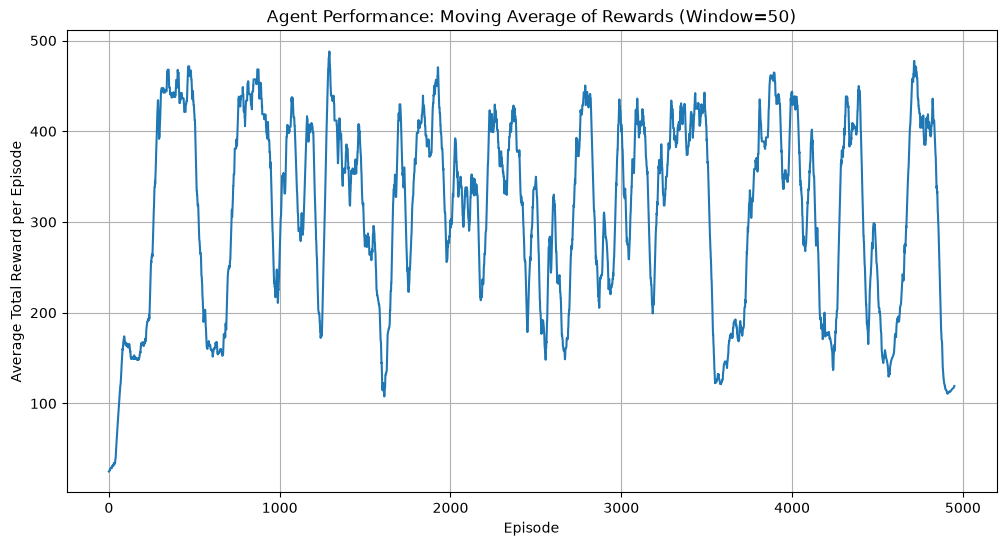

In [5]:
# plotting the moving average of rewards per episode
window_size = 50
moving_avg_rewards = np.convolve(reward_per_episode, np.ones(window_size)/window_size, mode='valid')

plt.figure(figsize=(12, 6))
plt.plot(moving_avg_rewards)
plt.title('Agent Performance: Moving Average of Rewards (Window=50)')
plt.xlabel('Episode')
plt.ylabel('Average Total Reward per Episode')
plt.grid(True)
plt.show()

In [6]:
# Save the learned actor and critic net
actor_filename = 'cart_pole_sac_actor.pt'
torch.save(actor_nn.state_dict(), actor_filename)

critic_filename = 'cart_pole_sac_critic.pt'
torch.save(critic_nn.state_dict(), critic_filename)

print("Actor and Critic nets saved!")

Actor and Critic nets saved!


In [7]:
# open the saved actor net
actor_filename = 'cart_pole_sac_actor.pt'

actor_policy = Actor(num_states=4, num_actions=2)

if os.path.exists(actor_filename):
    actor_policy.load_state_dict(torch.load(actor_filename))
    actor_policy.eval() # switch model to evaluation mode
    print(f"Policy net loaded from {actor_filename}")
else:
    print(f"Error: Policy file '{actor_filename}' not found. Please run the training code first.")

Policy net loaded from cart_pole_sac_actor.pt


In [8]:
# Evaluate the learned policy
env = gym.make("CartPole-v1", render_mode='human')

print("Evaluating learned policy...")
total_rewards = 0
num_eval_episodes = 3

for _ in range(num_eval_episodes):
    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    while (not terminated and not truncated):
        # For evaluation, use a greedy policy (no exploration)
        with torch.no_grad():
            action = actor_policy(state_to_nn_input(state).unsqueeze(0)).argmax().item()
        next_state, reward, terminated, truncated, info = env.step(action)
        episode_reward += float(reward)
        state = next_state

    total_rewards += episode_reward
print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")
env.close()

Evaluating learned policy...
Average reward over 3 evaluation episodes: 128.3333
